# Predicting an NFL wide receiver's next season

INST414 Module 5 (supervised learning). Each row is one wide receiver in one season (2015-2024) with at least 50 targets.
The features describe that season. The label is his receiving yards per game the **next** season, so this is a regression problem.

Run `src/collect.py` and `src/build_dataset.py` first. This notebook compares models with cross-validation,
tests the chosen one on the newest season pair (2024 -> 2025), and looks at the players it got most wrong.
It writes tables to `results/` and figures to `article/figures/`.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import LeaveOneGroupOut, cross_val_predict
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor

ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent
FIG = ROOT / "article" / "figures"
RES = ROOT / "results"
FIG.mkdir(parents=True, exist_ok=True)
RES.mkdir(exist_ok=True)

FEATURES = ["games", "targets_per_game", "target_share", "air_yards_share", "adot", "catch_rate",
            "yac_per_rec", "yards_per_target", "td_per_target", "epa_per_target", "yards_per_game",
            "age", "experience"]
LABEL = "next_yards_per_game"
SEED = 42

BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#898781"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e", "text.color": "#0b0b0b",
    "xtick.color": "#c3c2b7", "ytick.color": "#c3c2b7",
    "xtick.labelcolor": "#52514e", "ytick.labelcolor": "#52514e",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "savefig.dpi": 200, "savefig.bbox": "tight",
})

## Load the data

In [2]:
pairs = pd.read_csv(ROOT / "data" / "wr_season_pairs.csv")
seasons = pd.read_csv(ROOT / "data" / "wr_seasons_2015_2025.csv")

data = pairs[pairs["in_model"]].copy()
train = data[data["split"] == "train"].reset_index(drop=True)
test = data[data["split"] == "test"].reset_index(drop=True)
X_train, y_train = train[FEATURES], train[LABEL]
X_test, y_test = test[FEATURES], test[LABEL]

print("WR seasons with 50+ targets, 2015-2024:", len(pairs))
print("dropped (fewer than 8 games the next season):", int((~pairs["in_model"]).sum()))
print("rows used:", len(data))
print("train rows:", len(train), "| seasons", train["season"].min(), "to", train["season"].max())
print("test rows:", len(test), "| season", test["season"].unique().tolist(), "-> predicting", test["next_season"].unique().tolist())
print("label mean / sd in train:", round(y_train.mean(), 2), "/", round(y_train.std(), 2))
print("label mean / sd in test:", round(y_test.mean(), 2), "/", round(y_test.std(), 2))
print("same season's yards per game, train mean:", round(train["yards_per_game"].mean(), 2),
      "| test mean:", round(test["yards_per_game"].mean(), 2))
data[FEATURES + [LABEL]].describe().T[["mean", "std", "min", "max"]].round(2)

WR seasons with 50+ targets, 2015-2024: 855
dropped (fewer than 8 games the next season): 149
rows used: 706
train rows: 630 | seasons 2015 to 2023
test rows: 76 | season [2024] -> predicting [2025]
label mean / sd in train: 50.31 / 22.51
label mean / sd in test: 44.84 / 21.88
same season's yards per game, train mean: 54.25 | test mean: 51.09


,mean,std,min,max
games,14.75,2.12,7.00,17.00
targets_per_game,6.57,1.98,2.94,12.69
target_share,0.20,0.06,0.08,0.35
air_yards_share,0.26,0.09,0.01,0.52
adot,10.94,2.73,1.21,21.74
catch_rate,0.63,0.08,0.36,0.85
yac_per_rec,4.39,1.35,1.64,12.23
yards_per_target,8.15,1.42,3.62,13.79
td_per_target,0.05,0.03,0.00,0.15
epa_per_target,0.25,0.21,-0.37,1.07


## Baselines and cross-validation

Two baselines that use no machine learning:

- **League average:** predict the average label of the training rows for everyone.
- **Same as last season:** predict that he repeats this season's yards per game.

For cross-validation each fold holds out one whole season (9 folds), so the model is always scored on a season it never saw.

In [3]:
def scores(actual, predicted):
    return {"mae": mean_absolute_error(actual, predicted),
            "rmse": float(np.sqrt(mean_squared_error(actual, predicted))),
            "r2": r2_score(actual, predicted)}

by_season = LeaveOneGroupOut()

def cv_predict(model, cols=FEATURES):
    return cross_val_predict(model, train[cols], y_train, groups=train["season"], cv=by_season)

# league-average baseline, computed inside each fold
cv_average = np.zeros(len(train))
for fit_idx, held_idx in by_season.split(X_train, y_train, train["season"]):
    cv_average[held_idx] = y_train.iloc[fit_idx].mean()

cv_rows = [
    {"model": "Baseline: league average", "setting": "", **scores(y_train, cv_average)},
    {"model": "Baseline: same as last season", "setting": "", **scores(y_train, train["yards_per_game"])},
]
pd.DataFrame(cv_rows).round(3)

,model,setting,mae,rmse,r2
0,Baseline: league average,,18.266,22.545,-0.004
1,Baseline: same as last season,,14.450,17.730,0.379


## Models and hyperparameters

In [4]:
candidates = [("Linear regression", "", make_pipeline(StandardScaler(), LinearRegression()))]
for alpha in [0.1, 1, 3, 10, 30, 100, 300, 1000]:
    candidates.append(("Ridge regression", f"alpha={alpha}", make_pipeline(StandardScaler(), Ridge(alpha=alpha))))
for k in [1, 3, 5, 10, 15, 20, 30, 40, 60]:
    candidates.append(("k-nearest neighbors", f"k={k}",
                       make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=k))))
for depth in range(1, 11):
    candidates.append(("Decision tree", f"max_depth={depth}",
                       DecisionTreeRegressor(max_depth=depth, random_state=SEED)))
for leaf in [1, 3, 5, 10, 20]:
    candidates.append(("Random forest", f"min_samples_leaf={leaf}",
                       RandomForestRegressor(n_estimators=300, min_samples_leaf=leaf, random_state=SEED, n_jobs=-1)))

models = {}
cv_preds = {}
for name, setting, model in candidates:
    models[(name, setting)] = model
    cv_preds[(name, setting)] = cv_predict(model)
    cv_rows.append({"model": name, "setting": setting, **scores(y_train, cv_preds[(name, setting)])})

cv_results = pd.DataFrame(cv_rows)
cv_results.to_csv(RES / "cv_results.csv", index=False)

# best setting for each kind of model, by cross-validated mean absolute error
comparison = cv_results.sort_values("mae").drop_duplicates("model").reset_index(drop=True)
comparison.to_csv(RES / "model_comparison.csv", index=False)
comparison.round(3)

,model,setting,mae,rmse,r2
0,Ridge regression,alpha=30,13.049,16.136,0.486
1,Linear regression,,13.084,16.176,0.483
2,k-nearest neighbors,k=30,13.417,16.447,0.465
3,Random forest,min_samples_leaf=5,13.454,16.598,0.456
4,Decision tree,max_depth=3,14.410,17.667,0.383
5,Baseline: same as last season,,14.450,17.730,0.379
6,Baseline: league average,,18.266,22.545,-0.004


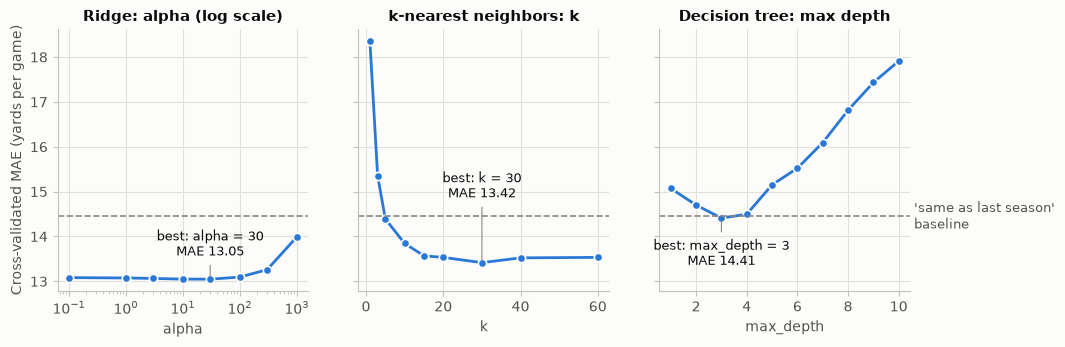

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4), sharey=True)
same_as_last = cv_results.loc[cv_results["model"] == "Baseline: same as last season", "mae"].iloc[0]
panels = [("Ridge regression", "alpha", "Ridge: alpha (log scale)", 14, "bottom"),
          ("k-nearest neighbors", "k", "k-nearest neighbors: k", 44, "bottom"),
          ("Decision tree", "max_depth", "Decision tree: max depth", -14, "top")]
for ax, (name, param, title, label_dy, label_va) in zip(axes, panels):
    rows = cv_results[cv_results["model"] == name].copy()
    rows["value"] = rows["setting"].str.split("=").str[1].astype(float)
    ax.plot(rows["value"], rows["mae"], color=BLUE, linewidth=2, marker="o", markersize=6,
            markeredgecolor="#fcfcfb", markeredgewidth=1.2)
    best = rows.loc[rows["mae"].idxmin()]
    ax.annotate(f"best: {param} = {best['value']:g}\nMAE {best['mae']:.2f}", (best["value"], best["mae"]),
                textcoords="offset points", xytext=(0, label_dy), ha="center", va=label_va, fontsize=9, color="#0b0b0b",
                arrowprops={"arrowstyle": "-", "color": "#898781", "linewidth": 0.8})
    ax.axhline(same_as_last, color=GRAY, linewidth=1.2, linestyle="--")
    if param == "alpha":
        ax.set_xscale("log")
    ax.set_title(title)
    ax.set_xlabel(param)
axes[0].set_ylabel("Cross-validated MAE (yards per game)")
axes[2].text(axes[2].get_xlim()[1], same_as_last, " 'same as last season'\n baseline", va="center", ha="left",
             fontsize=9, color="#52514e")
fig.savefig(FIG / "hyperparameters.png")
plt.show()

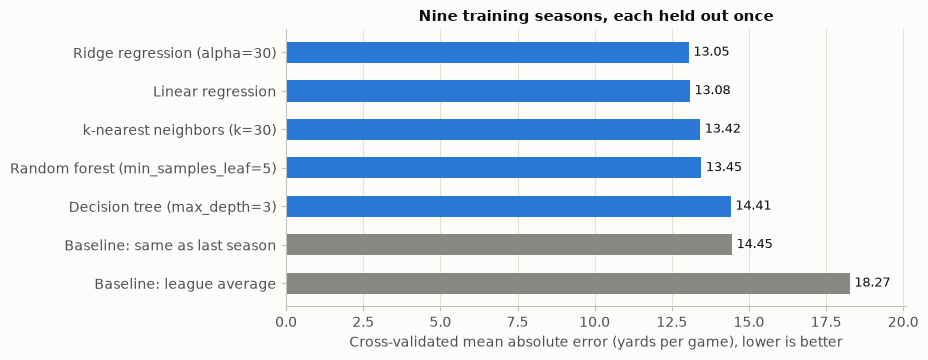

In [6]:
chart = comparison.sort_values("mae", ascending=False)
labels = [m + (f" ({s})" if s else "") for m, s in zip(chart["model"], chart["setting"])]
colors = [GRAY if m.startswith("Baseline") else BLUE for m in chart["model"]]

fig, ax = plt.subplots(figsize=(8, 3.6))
bars = ax.barh(labels, chart["mae"], color=colors, height=0.55)
for bar, value in zip(bars, chart["mae"]):
    ax.text(value + 0.15, bar.get_y() + bar.get_height() / 2, f"{value:.2f}", va="center", fontsize=9)
ax.set_xlabel("Cross-validated mean absolute error (yards per game), lower is better")
ax.set_xlim(0, chart["mae"].max() * 1.1)
ax.grid(axis="y", visible=False)
ax.set_title("Nine training seasons, each held out once")
fig.savefig(FIG / "model_comparison.png")
plt.show()

## Final model on the held-out season

The model with the lowest cross-validated error is refit on all nine training seasons and scored once on the
2024 -> 2025 rows, which were not used for anything above.

In [7]:
best_row = comparison[~comparison["model"].str.startswith("Baseline")].iloc[0]
best_key = (best_row["model"], best_row["setting"])
print("chosen by cross-validation:", best_key)

final_model = models[best_key]
final_model.fit(X_train, y_train)
test_pred = final_model.predict(X_test)

test_rows = [
    {"model": "Baseline: league average", **scores(y_test, np.full(len(test), y_train.mean()))},
    {"model": "Baseline: same as last season", **scores(y_test, test["yards_per_game"])},
    {"model": f"{best_key[0]} ({best_key[1]}) - chosen", **scores(y_test, test_pred)},
]
# the other kinds of model at their best cross-validated setting, shown for transparency only
for _, row in comparison.iterrows():
    key = (row["model"], row["setting"])
    if row["model"].startswith("Baseline") or key == best_key:
        continue
    other = models[key].fit(X_train, y_train)
    label = row["model"] + (f" ({row['setting']})" if row["setting"] else "")
    test_rows.append({"model": label + " - not chosen", **scores(y_test, other.predict(X_test))})

test_metrics = pd.DataFrame(test_rows)
test_metrics.to_csv(RES / "test_metrics.csv", index=False)
test_metrics.round(3)

chosen by cross-validation: ('Ridge regression', 'alpha=30')


,model,mae,rmse,r2
0,Baseline: league average,18.339,22.416,-0.063
1,Baseline: same as last season,14.200,17.935,0.319
2,Ridge regression (alpha=30) - chosen,12.951,15.705,0.478
3,Linear regression - not chosen,12.953,15.723,0.477
4,k-nearest neighbors (k=30) - not chosen,13.614,16.331,0.436
5,Random forest (min_samples_leaf=5) - not chosen,13.068,16.309,0.437
6,Decision tree (max_depth=3) - not chosen,12.664,16.807,0.402


In [8]:
predictions = test[["player", "season", "next_season", "team", "next_team", "qb", "next_qb", "changed_team", "changed_qb",
                    "age", "games", "next_games", "yards_per_game", "targets_per_game", "next_targets_per_game",
                    "target_share", "next_target_share"]].copy()
predictions["predicted"] = test_pred
predictions["actual"] = y_test.values
predictions["error"] = predictions["predicted"] - predictions["actual"]      # positive = model too high
predictions["abs_error"] = predictions["error"].abs()
predictions = predictions.sort_values("abs_error", ascending=False).reset_index(drop=True)
predictions.to_csv(RES / "test_predictions.csv", index=False)

print("mean error (predicted - actual):", round(predictions["error"].mean(), 2))
print("share within 10 yards per game:", round((predictions["abs_error"] <= 10).mean(), 3))
print("players missed by more than 20 yards per game:", int((predictions["abs_error"] > 20).sum()), "of", len(predictions))
print("predicted range:", round(predictions["predicted"].min(), 1), "to", round(predictions["predicted"].max(), 1))
print("actual range:", round(predictions["actual"].min(), 1), "to", round(predictions["actual"].max(), 1))

mean error (predicted - actual): 4.93
share within 10 yards per game: 0.421
players missed by more than 20 yards per game: 17 of 76
predicted range: 18.0 to 87.2
actual range: 6.8 to 107.2


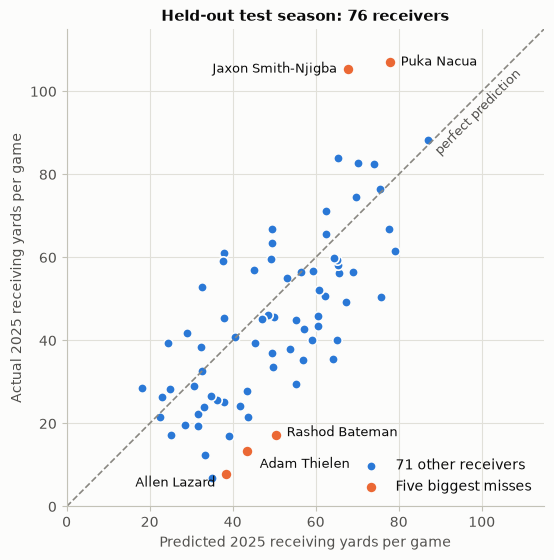

In [9]:
worst5 = predictions.head(5)
rest = predictions.iloc[5:]

fig, ax = plt.subplots(figsize=(6.6, 6.2))
ax.plot([0, 115], [0, 115], color=GRAY, linewidth=1.2, linestyle="--")
ax.text(99, 95, "perfect prediction", color="#52514e", fontsize=9, rotation=45, ha="center", va="center")
ax.scatter(rest["predicted"], rest["actual"], s=46, color=BLUE, edgecolor="#fcfcfb", linewidth=1.2,
           label=f"{len(rest)} other receivers")
ax.scatter(worst5["predicted"], worst5["actual"], s=64, color=ORANGE, edgecolor="#fcfcfb", linewidth=1.2,
           label="Five biggest misses")
offsets = {"Jaxon Smith-Njigba": (-8, 0, "right"), "Puka Nacua": (8, 0, "left"), "Rashod Bateman": (8, 2, "left"),
           "Allen Lazard": (-8, -6, "right"), "Adam Thielen": (9, -9, "left")}
for _, row in worst5.iterrows():
    dx, dy, ha = offsets.get(row["player"], (8, 0, "left"))
    ax.annotate(row["player"], (row["predicted"], row["actual"]), textcoords="offset points", xytext=(dx, dy),
                ha=ha, va="center", fontsize=9)
ax.set_xlim(0, 115)
ax.set_ylim(0, 115)
ax.set_aspect("equal")
ax.set_xlabel("Predicted 2025 receiving yards per game")
ax.set_ylabel("Actual 2025 receiving yards per game")
ax.set_title("Held-out test season: 76 receivers")
ax.legend(loc="lower right", frameon=False)
fig.savefig(FIG / "predicted_vs_actual.png")
plt.show()

## Which features carry the prediction

The features overlap a lot (targets per game and yards per game move together), so single coefficients are hard to read.
I also refit the chosen kind of model on one **group** of features at a time and on everything except that group.

In [10]:
ridge = final_model[-1]
coefficients = pd.Series(ridge.coef_, index=FEATURES).sort_values(ascending=False)
coefficients.round(2).to_csv(RES / "coefficients.csv", header=["yards_per_game_change_per_1_sd"])
print("Chosen model, change in predicted yards per game for a 1 standard deviation increase in each feature:")
print(coefficients.round(2).to_string())

Chosen model, change in predicted yards per game for a 1 standard deviation increase in each feature:
yards_per_game      5.13
targets_per_game    4.75
air_yards_share     3.21
target_share        2.78
epa_per_target      1.70
catch_rate          1.63
yac_per_rec         1.51
games               1.45
td_per_target       1.43
adot                1.35
experience          0.07
yards_per_target   -1.29
age                -3.45


In [11]:
groups = {
    "Last season's yards per game": ["yards_per_game"],
    "Usage (targets per game, target share, air yards share)": ["targets_per_game", "target_share", "air_yards_share"],
    "Efficiency (catch rate, yards/target, YAC, TD rate, EPA/target)": ["catch_rate", "yac_per_rec", "yards_per_target", "td_per_target", "epa_per_target"],
    "Age and experience": ["age", "experience"],
    "Games played and target depth": ["games", "adot"],
}
alpha = float(best_key[1].split("=")[1])

def group_score(cols):
    return scores(y_train, cv_predict(make_pipeline(StandardScaler(), Ridge(alpha=alpha)), cols))

full = scores(y_train, cv_preds[best_key])
group_rows = []
for name, cols in groups.items():
    only = group_score(cols)
    without = group_score([f for f in FEATURES if f not in cols])
    group_rows.append({"group": name, "only_mae": only["mae"], "only_r2": only["r2"],
                       "without_mae": without["mae"], "without_r2": without["r2"],
                       "mae_added_when_removed": without["mae"] - full["mae"]})
group_results = pd.DataFrame(group_rows)
group_results.to_csv(RES / "feature_groups.csv", index=False)
print("all 13 features: MAE", round(full["mae"], 2), "R2", round(full["r2"], 3))
group_results.round(3)

all 13 features: MAE 13.05 R2 0.486


,group,only_mae,only_r2,without_mae,without_r2,mae_added_when_removed
0,Last season's yards per game,13.780,0.438,13.080,0.483,0.031
1,"Usage (targets per game, target share, air yar...",14.069,0.408,13.219,0.472,0.170
2,"Efficiency (catch rate, yards/target, YAC, TD ...",17.422,0.103,13.192,0.478,0.143
3,Age and experience,17.987,0.022,13.358,0.464,0.309
4,Games played and target depth,18.110,0.006,13.109,0.483,0.060


                                                          group  error_removed
                                  Games played and target depth           0.16
                                             Age and experience           0.28
Efficiency (catch rate, yards/target, YAC, TD rate, EPA/target)           0.84
        Usage (targets per game, target share, air yards share)           4.20
                                   Last season's yards per game           4.49
                                       All 13 features together           5.22


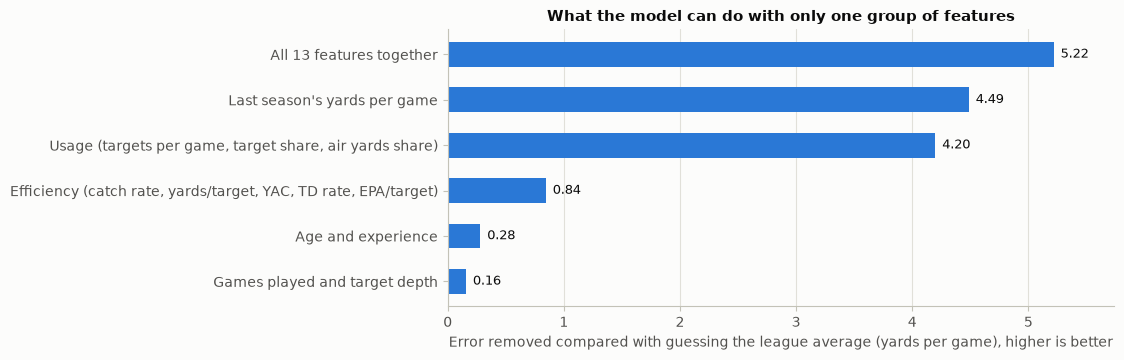

In [12]:
# how much of the league-average baseline's error each group removes when it is the only thing the model sees
average_mae = cv_results.loc[cv_results["model"] == "Baseline: league average", "mae"].iloc[0]
chart = pd.DataFrame({
    "group": ["All 13 features together"] + group_results["group"].tolist(),
    "error_removed": [average_mae - full["mae"]] + (average_mae - group_results["only_mae"]).tolist(),
}).sort_values("error_removed")
print(chart.round(2).to_string(index=False))

fig, ax = plt.subplots(figsize=(8.6, 3.6))
bars = ax.barh(chart["group"], chart["error_removed"], color=BLUE, height=0.55)
for bar, value in zip(bars, chart["error_removed"]):
    ax.text(value + 0.06, bar.get_y() + bar.get_height() / 2, f"{value:.2f}", va="center", fontsize=9)
ax.set_xlim(0, chart["error_removed"].max() * 1.1)
ax.set_xlabel("Error removed compared with guessing the league average (yards per game), higher is better")
ax.set_title("What the model can do with only one group of features")
ax.grid(axis="y", visible=False)
fig.savefig(FIG / "feature_groups.png")
plt.show()

## Where the model was wrong

For a regression model "wrong" is a matter of degree, so I look at the five largest errors on the test season,
with context that the model did not get to see (next season's team, quarterback and target share).

In [13]:
show = worst5[["player", "age", "games", "yards_per_game", "predicted", "actual", "error",
               "target_share", "next_target_share", "team", "next_team", "qb", "next_qb", "next_games"]]
worst5.to_csv(RES / "biggest_misses.csv", index=False)
show.round(3)

,player,age,games,yards_per_game,predicted,actual,error,target_share,next_target_share,team,next_team,qb,next_qb,next_games
0,Jaxon Smith-Njigba,23.546,17,66.471,67.819,105.471,-37.651,0.241,0.358,SEA,SEA,Geno Smith,Sam Darnold,17
1,Rashod Bateman,25.758,16,47.250,50.329,17.231,33.098,0.171,0.114,BAL,BAL,Lamar Jackson,Lamar Jackson,13
2,Allen Lazard,29.725,12,44.167,38.453,7.778,30.675,0.139,0.062,NYJ,NYJ,Aaron Rodgers,Justin Fields,9
3,Adam Thielen,35.028,10,61.500,43.517,13.286,30.231,0.202,0.078,CAR,MIN,Bryce Young,J.J. McCarthy,14
4,Puka Nacua,24.260,11,90.000,77.807,107.188,-29.381,0.299,0.303,LA,LA,Matthew Stafford,Matthew Stafford,16


In [14]:
# the other wide receivers on those teams, before and after (context only)
for _, row in worst5.iterrows():
    print(row["player"])
    for team, year in [(row["team"], 2024), (row["next_team"], 2025)]:
        top = seasons[(seasons["team"] == team) & (seasons["season"] == year)].sort_values("targets", ascending=False).head(4)
        print("  ", team, year, "| QB", top["qb"].iloc[0], "|",
              "; ".join(f"{p} {int(t)} targets" for p, t in zip(top["player"], top["targets"])))
    history = seasons[(seasons["player"] == row["player"]) & (seasons["season"] >= 2022)]
    for _, h in history.iterrows():
        print(f"     {h['season']} {h['team']} (QB {h['qb']}): {h['games']} games, {int(h['targets'])} targets, "
              f"{int(h['receiving_yards'])} yards, {int(h['receiving_tds'])} TD, "
              f"{h['yards_per_target']:.2f} yards/target, target share {h['target_share']:.3f}")

# where two of Seattle's 2024 receivers were in 2025
for name in ["DK Metcalf", "Tyler Lockett", "Cooper Kupp"]:
    rows = seasons[(seasons["player"] == name) & (seasons["season"].isin([2024, 2025]))]
    print(name, [(int(s), t, int(g)) for s, t, g in zip(rows["season"], rows["team"], rows["games"])])

# how unusual were these five on the features the model saw?
for col in ["yards_per_target", "td_per_target", "age"]:
    ranks = test[col].rank(pct=True)
    print(col, "percentile in the test set:",
          {p: round(float(ranks[test["player"] == p].iloc[0]), 2) for p in worst5["player"]})
print("training rows aged 34 or older:", int((train["age"] >= 34).sum()), "of", len(train))
print("oldest test players:", test.sort_values("age", ascending=False)[["player", "age"]].head(3).round(1).values.tolist())

Jaxon Smith-Njigba
   SEA 2024 | QB Geno Smith | Jaxon Smith-Njigba 137 targets; DK Metcalf 108 targets; Tyler Lockett 74 targets; Jake Bobo 17 targets
   SEA 2025 | QB Sam Darnold | Jaxon Smith-Njigba 163 targets; Cooper Kupp 70 targets; Tory Horton 22 targets; Cody White 4 targets
     2023 SEA (QB Geno Smith): 17 games, 93 targets, 628 yards, 4 TD, 6.75 yards/target, target share 0.170
     2024 SEA (QB Geno Smith): 17 games, 137 targets, 1130 yards, 6 TD, 8.25 yards/target, target share 0.241
     2025 SEA (QB Sam Darnold): 17 games, 163 targets, 1793 yards, 10 TD, 11.00 yards/target, target share 0.358
Rashod Bateman
   BAL 2024 | QB Lamar Jackson | Zay Flowers 116 targets; Rashod Bateman 72 targets; Nelson Agholor 29 targets; Tylan Wallace 12 targets
   BAL 2025 | QB Lamar Jackson | Zay Flowers 118 targets; DeAndre Hopkins 39 targets; Rashod Bateman 38 targets; Tylan Wallace 8 targets
     2022 BAL (QB Lamar Jackson): 6 games, 28 targets, 285 yards, 2 TD, 10.18 yards/target, targ

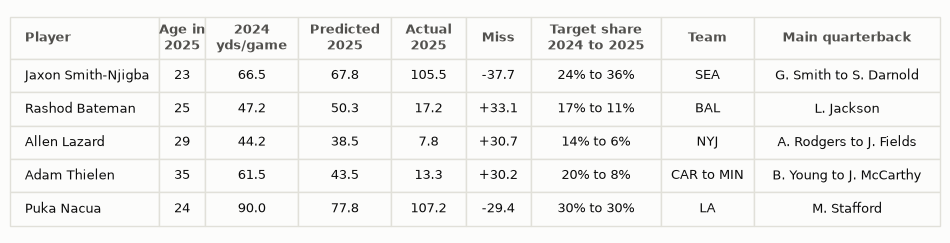

In [15]:
table = worst5.copy()
def short(name):
    first, last = name.split(" ", 1)
    return first[0] + ". " + last
cell_text = []
for _, row in table.iterrows():
    team = row["team"] if row["team"] == row["next_team"] else f"{row['team']} to {row['next_team']}"
    qb = short(row["qb"]) if row["qb"] == row["next_qb"] else f"{short(row['qb'])} to {short(row['next_qb'])}"
    cell_text.append([row["player"], f"{int(row['age'])}", f"{row['yards_per_game']:.1f}", f"{row['predicted']:.1f}",
                      f"{row['actual']:.1f}", f"{row['error']:+.1f}",
                      f"{row['target_share']:.0%} to {row['next_target_share']:.0%}", team, qb])
columns = ["Player", "Age in\n2025", "2024\nyds/game", "Predicted\n2025", "Actual\n2025", "Miss",
           "Target share\n2024 to 2025", "Team", "Main quarterback"]

fig, ax = plt.subplots(figsize=(12, 2.9))
ax.axis("off")
tbl = ax.table(cellText=cell_text, colLabels=columns, loc="center", cellLoc="center",
               colWidths=[0.16, 0.05, 0.10, 0.10, 0.08, 0.07, 0.14, 0.10, 0.20])
tbl.auto_set_font_size(False)
tbl.set_fontsize(9.5)
tbl.scale(1, 2.0)
for (r, c), cell in tbl.get_celld().items():
    cell.set_edgecolor("#e1e0d9")
    cell.set_facecolor("#fcfcfb")
    if r == 0:
        cell.set_text_props(weight="bold", color="#52514e")
        cell.set_height(cell.get_height() * 1.25)
    if c == 0:
        cell.set_text_props(ha="left")
        cell._loc = "left"
fig.savefig(FIG / "biggest_misses_table.png")
plt.show()

In [16]:
# does the error depend on things that changed after the season? (cross-validated predictions for train)
train_cv = train.assign(cv_pred=cv_preds[best_key])
train_cv["abs_error"] = (train_cv["cv_pred"] - train_cv[LABEL]).abs()
context_rows = []
for col in ["changed_team", "changed_qb"]:
    for value in [False, True]:
        tr = train_cv[train_cv[col] == value]
        te = predictions[predictions[col] == value]
        context_rows.append({"what": col, "changed": value, "train_n": len(tr), "train_cv_mae": tr["abs_error"].mean(),
                             "test_n": len(te), "test_mae": te["abs_error"].mean()})
context = pd.DataFrame(context_rows)
context.to_csv(RES / "error_by_context.csv", index=False)
print(context.round(2).to_string(index=False))

# the model pulls extreme seasons toward the middle
stars = predictions[predictions["actual"] >= 80]
print()
print("test receivers at 80+ actual yards per game:", len(stars), "| mean error", round(stars["error"].mean(), 1))
print(stars[["player", "yards_per_game", "predicted", "actual", "error"]].round(1).to_string(index=False))
high = train[train["yards_per_game"] >= 85]
print("training receivers at 85+ yards per game:", len(high), "| mean that season", round(high["yards_per_game"].mean(), 1),
      "| mean next season", round(high[LABEL].mean(), 1))
ranked = data.sort_values(LABEL, ascending=False).reset_index(drop=True)
for name in ["Puka Nacua", "Jaxon Smith-Njigba"]:
    spot = ranked[(ranked["player"] == name) & (ranked["next_season"] == 2025)].index[0] + 1
    print(name, "2025 is label rank", spot, "of", len(ranked))

# season by season: chosen model vs 'same as last season'
season_rows = []
for season, g in train_cv.groupby("season"):
    season_rows.append({"season": season, "n": len(g), "model_mae": g["abs_error"].mean(),
                        "same_as_last_season_mae": mean_absolute_error(g[LABEL], g["yards_per_game"])})
per_season = pd.DataFrame(season_rows)
per_season.to_csv(RES / "cv_by_season.csv", index=False)
print()
print(per_season.round(2).to_string(index=False))
print("seasons where the model beat 'same as last season':",
      int((per_season["model_mae"] < per_season["same_as_last_season_mae"]).sum()), "of", len(per_season))

        what  changed  train_n  train_cv_mae  test_n  test_mae
changed_team    False      487         12.54      57     13.40
changed_team     True      143         14.77      19     11.60
  changed_qb    False      322         12.59      35     12.56
  changed_qb     True      308         13.53      41     13.28

test receivers at 80+ actual yards per game: 6 | mean error -18.0
            player  yards_per_game  predicted  actual  error
Jaxon Smith-Njigba            66.5       67.8   105.5  -37.7
        Puka Nacua            90.0       77.8   107.2  -29.4
    George Pickens            64.3       65.5    84.1  -18.6
       CeeDee Lamb            79.6       70.1    82.8  -12.7
 Amon-Ra St. Brown            74.3       74.0    82.4   -8.4
     Ja'Marr Chase           100.5       87.2    88.2   -1.1
training receivers at 85+ yards per game: 55 | mean that season 94.3 | mean next season 77.3
Puka Nacua 2025 is label rank 6 of 706
Jaxon Smith-Njigba 2025 is label rank 8 of 706

 season  n 

In [17]:
def metric(table, name):
    row = table[table["model"].str.startswith(name)].iloc[0]
    return {"mae": round(float(row["mae"]), 3), "rmse": round(float(row["rmse"]), 3), "r2": round(float(row["r2"]), 3)}

summary = {
    "rows_candidates": int(len(pairs)),
    "rows_dropped_under_8_games_next_season": int((~pairs["in_model"]).sum()),
    "rows_used": int(len(data)),
    "train_rows": int(len(train)),
    "test_rows": int(len(test)),
    "label_mean_train": round(float(y_train.mean()), 2),
    "label_mean_test": round(float(y_test.mean()), 2),
    "this_season_mean_train": round(float(train["yards_per_game"].mean()), 2),
    "this_season_mean_test": round(float(test["yards_per_game"].mean()), 2),
    "chosen_model": f"{best_key[0]} ({best_key[1]})",
    "cv": {row["model"] + (f" ({row['setting']})" if row["setting"] else ""):
           {"mae": round(float(row["mae"]), 3), "rmse": round(float(row["rmse"]), 3), "r2": round(float(row["r2"]), 3)}
           for _, row in comparison.iterrows()},
    "test": {row["model"]: {"mae": round(float(row["mae"]), 3), "rmse": round(float(row["rmse"]), 3),
                            "r2": round(float(row["r2"]), 3)} for _, row in test_metrics.iterrows()},
    "test_mean_error": round(float(predictions["error"].mean()), 2),
    "test_share_within_10": round(float((predictions["abs_error"] <= 10).mean()), 3),
    "test_missed_by_more_than_20": int((predictions["abs_error"] > 20).sum()),
    "biggest_misses": [{"player": r["player"], "predicted": round(float(r["predicted"]), 1),
                        "actual": round(float(r["actual"]), 1), "error": round(float(r["error"]), 1)}
                       for _, r in worst5.iterrows()],
}
(RES / "summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
print(json.dumps(summary, indent=2))

{
  "rows_candidates": 855,
  "rows_dropped_under_8_games_next_season": 149,
  "rows_used": 706,
  "train_rows": 630,
  "test_rows": 76,
  "label_mean_train": 50.31,
  "label_mean_test": 44.84,
  "this_season_mean_train": 54.25,
  "this_season_mean_test": 51.09,
  "chosen_model": "Ridge regression (alpha=30)",
  "cv": {
    "Ridge regression (alpha=30)": {
      "mae": 13.049,
      "rmse": 16.136,
      "r2": 0.486
    },
    "Linear regression": {
      "mae": 13.084,
      "rmse": 16.176,
      "r2": 0.483
    },
    "k-nearest neighbors (k=30)": {
      "mae": 13.417,
      "rmse": 16.447,
      "r2": 0.465
    },
    "Random forest (min_samples_leaf=5)": {
      "mae": 13.454,
      "rmse": 16.598,
      "r2": 0.456
    },
    "Decision tree (max_depth=3)": {
      "mae": 14.41,
      "rmse": 17.667,
      "r2": 0.383
    },
    "Baseline: same as last season": {
      "mae": 14.45,
      "rmse": 17.73,
      "r2": 0.379
    },
    "Baseline: league average": {
      "mae": 18.266